# 多受试者 Udeco2 / Udeco3 自适应状态分析

目标：按自然平台分别识别 Udeco2、Udeco3 的 H/M/L 状态，保留 100–200 ms 短状态，校正慢变 M(t)，并输出可追溯的验证图、批量统计和 Excel。

成功标准：单文件图可肉眼检查状态；批处理与绘图调用同一 `classify_udeco`；坏样本只记录 QC、不阻断其他样本。

In [1]:
# Cell 1 - Import：只导入本项目唯一算法模块
from __future__ import annotations

import os
import platform
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from udeco_analysis import (
    AnalysisConfig,
    analyze_all_subjects,
    analyze_sample,
    export_excel,
    load_udeco_sample,
    plot_validation,
    select_validation_candidates,
)

print(f'Python: {platform.python_version()} | 工作目录: {Path.cwd()}')

Python: 3.10.20 | 工作目录: d:\MHLcode


## 用户参数区

所有时间量均使用秒，并在算法内部按采样率换算为采样点。先修改路径；第一轮只运行 Validation，人工确认后再把 `RUN_BATCH` 改为 `True`。

In [2]:
# Cell 2 - User configuration
DATA_ROOT = Path(os.environ.get('UDECO_DATA_ROOT', 'D:\\MHLcode\\subject_data'))
SUBJECTS = ['ts', 'lyx', 'lzj', 'cgx', 'pjy', 'hjy']

# 原始采样率：change6/Pydisplay 协议固定 100 Hz；改变后所有秒参数自动换算。
FS_HZ = 100

# 轻度中值滤波：增大更抗尖峰但更易钝化短状态；减小更保真但更敏感。建议 0.01–0.03 s。
MEDIAN_FILTER_SEC = 0.03
# 初始 M 锚定时长：增大估计更稳但更可能混入后续状态；减小更局部但噪声更大。协议默认 30 s。
INITIAL_M_SEC = 30.0
# 变化点左右中位数窗口：增大更稳但可能吞短平台；减小更灵敏。建议 0.02–0.04 s。
CHANGE_WINDOW_SEC = 0.03
# 变化点噪声倍率：增大减少误检；减小可发现较小阶跃但会增加切段。建议 4–7。
CHANGE_THRESHOLD_SIGMA = 5.0
# 相邻峰合并距离：增大可合并同一阶跃周围峰；过大会合并短状态两端。建议 0.02–0.05 s。
CHANGE_PEAK_MERGE_SEC = 0.04
# 极短异常参考：增大更能抑制尖峰但可能丢短状态；减小更保守。建议 0.04–0.08 s。
MIN_PLATFORM_SEC = 0.06
# 初始状态中心分离倍率：增大更难新增 H/L；减小更易把波动当状态。建议 3–6。
STATE_SEPARATION_SIGMA = 4.0
# 可信 M anchor 残差倍率：增大能跟踪更大漂移但可能吸收 H/L；减小更纯但 anchor 更少。建议 2–3。
M_ANCHOR_SIGMA = 2.5
# M(t) 平滑尺度：增大基线更慢、更不跟随短状态；减小更能跟漂移但可能追随阶跃。建议 5–20 s。
M_BASELINE_SMOOTH_SEC = 10.0
# M anchor 最大迭代轮数：增大可逐步覆盖更大漂移但耗时增加；建议 3–7。
M_BASELINE_MAX_ITER = 5
# 进入 H/L 的 sigma 倍率：增大更保守；减小更灵敏。必须大于 EXIT_SIGMA，建议 3.5–6。
ENTER_SIGMA = 4.0
# 退出 H/L 的 sigma 倍率：增大更早退出，减小滞回更强。建议 1.5–3。
EXIT_SIGMA = 2.0
# 可选 GMM/BIC：True 时只辅助 segment center；默认 False 保持透明可解释。
USE_GMM = False

# 运动检测：沿用 change6 的 ACC 规则；窗口增大更稳但边界更钝，连续窗增大更保守。
MOTION_CALIBRATION_SEC = 30.0
MOTION_WINDOW_SEC = 8.0
MOTION_STEP_SEC = 1.0
MOTION_THRESHOLD_SIGMA = 3.0
MOTION_TRANSITION_WINDOWS = 6

# 单文件验证：也可设置环境变量 UDECO_VALIDATION_FILE；留空时相关 cell 安全跳过。
_validation_text = os.environ.get('UDECO_VALIDATION_FILE', '').strip()
# VALIDATION_FILE = Path(_validation_text) if _validation_text else None
VALIDATION_FILE = DATA_ROOT / "ts" / "ts_write_1_sensor.csv"
SHOW_DEBUG_INFO = True

# 批量开关：Validation 人工确认前保持 False；True 时分析 SUBJECTS 并写 Excel。
RUN_BATCH = False
OUTPUT_EXCEL = Path(os.environ.get('UDECO_OUTPUT_EXCEL', 'outputs/udeco_state_results.xlsx'))

## 算法与输入契约

读取严格配对的 `{subject}_{motion}_{index}_sensor.csv` / `_HRdata.csv`；共享标定为 `DATA_ROOT/ck.mat`。公式为 `Udeco2=(Uh2-Uc2)/(c2-Uc2)`、`Udeco3=(Uh3-Uc3)/(c3-Uc3)`。

主流程：轻度 median → M0/MAD → 短窗变化点 → 自然 segments → 迭代 M(t) → residual → segment 级 hysteresis → 样本标签与统计。

In [3]:
# Cell 3 - 将用户参数集中封装；模块内部不再散落 magic numbers
CONFIG = AnalysisConfig(
    median_filter_sec=MEDIAN_FILTER_SEC,
    initial_m_sec=INITIAL_M_SEC,
    change_window_sec=CHANGE_WINDOW_SEC,
    change_threshold_sigma=CHANGE_THRESHOLD_SIGMA,
    change_peak_merge_sec=CHANGE_PEAK_MERGE_SEC,
    min_platform_sec=MIN_PLATFORM_SEC,
    state_separation_sigma=STATE_SEPARATION_SIGMA,
    m_anchor_sigma=M_ANCHOR_SIGMA,
    m_baseline_smooth_sec=M_BASELINE_SMOOTH_SEC,
    m_baseline_max_iter=M_BASELINE_MAX_ITER,
    enter_sigma=ENTER_SIGMA,
    exit_sigma=EXIT_SIGMA,
    use_gmm=USE_GMM,
    motion_calibration_sec=MOTION_CALIBRATION_SEC,
    motion_window_sec=MOTION_WINDOW_SEC,
    motion_step_sec=MOTION_STEP_SEC,
    motion_threshold_sigma=MOTION_THRESHOLD_SIGMA,
    motion_transition_windows=MOTION_TRANSITION_WINDOWS,
)
display(pd.Series(asdict(CONFIG), name='value').to_frame())

,value
median_filter_sec,0.03
initial_m_sec,30.0
change_window_sec,0.03
change_threshold_sigma,5.0
change_peak_merge_sec,0.04
min_platform_sec,0.06
state_separation_sigma,4.0
m_anchor_sigma,2.5
m_baseline_smooth_sec,10.0
m_baseline_max_iter,5


## Step 1：确认单文件读取

本 cell 只核对时间轴、标定映射与序号/分母 QC，不执行分类。

In [4]:
validation_loaded = None
if VALIDATION_FILE is None:
    print('未设置 VALIDATION_FILE：跳过单文件读取检查。')
elif not VALIDATION_FILE.is_file():
    print(f'VALIDATION_FILE 不存在：{VALIDATION_FILE}')
else:
    validation_loaded = load_udeco_sample(VALIDATION_FILE, data_root=DATA_ROOT, fs=FS_HZ)
    display(pd.Series({
        'sample_name': validation_loaded.sample_name,
        'n_samples': len(validation_loaded.time_s),
        'duration_s': len(validation_loaded.time_s) / validation_loaded.fs,
        'fs_hz': validation_loaded.fs,
        'sequence_interpolated': int(validation_loaded.qc['InterpFlag'].sum()),
        'near_zero_denominator': int(validation_loaded.qc['ud_denominator_near_zero'].sum()),
    }, name='value').to_frame())

,value
sample_name,ts_write_1
n_samples,19515
duration_s,195.15
fs_hz,100
sequence_interpolated,0
near_zero_denominator,0


## Validation / Manual Inspection

修改 `VALIDATION_FILE` 后，只需重跑参数、CONFIG、本节三个 cell。主图始终为 Udeco2/Udeco3 两行，H/M/L 用背景状态带表示。

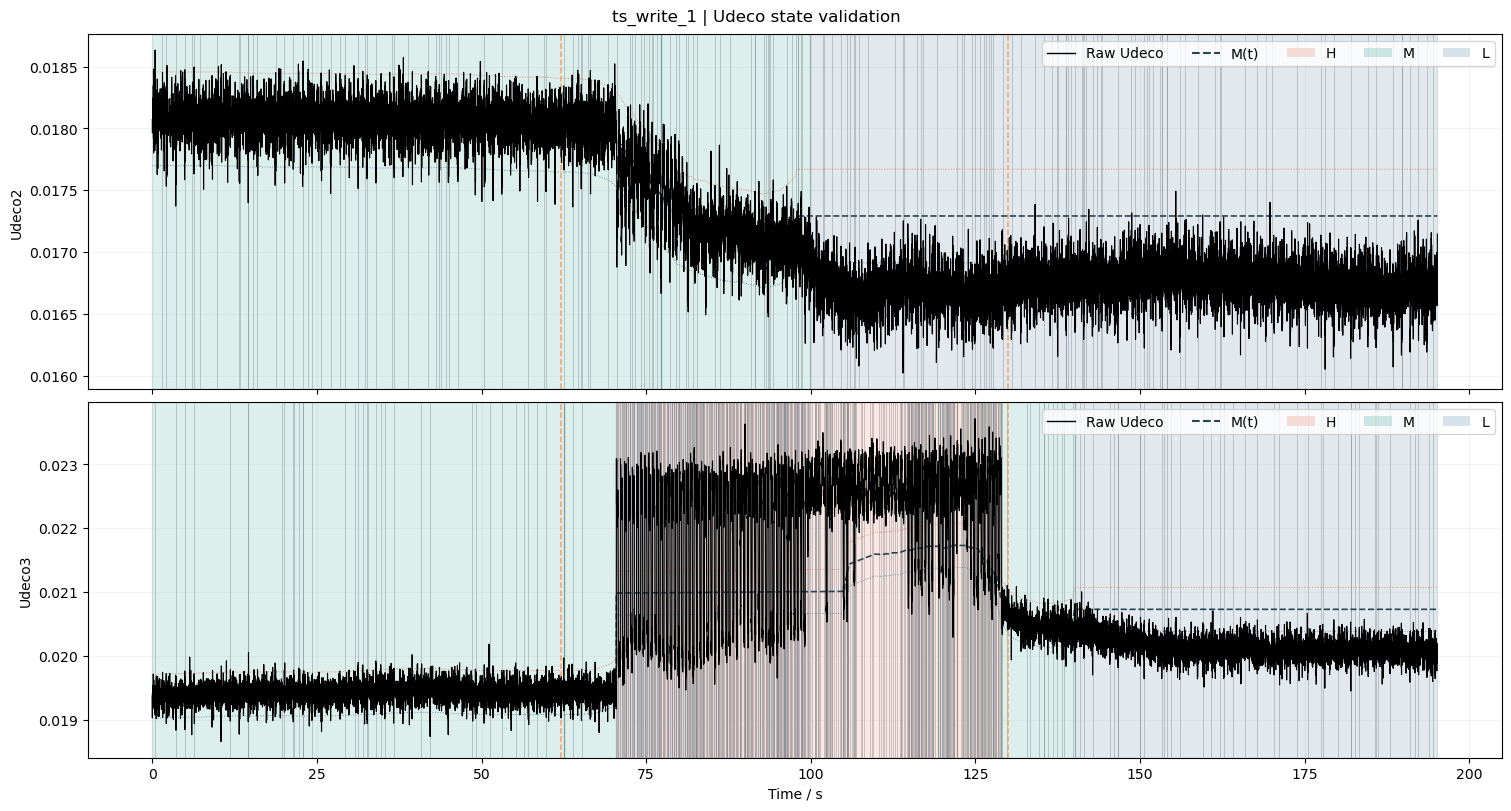

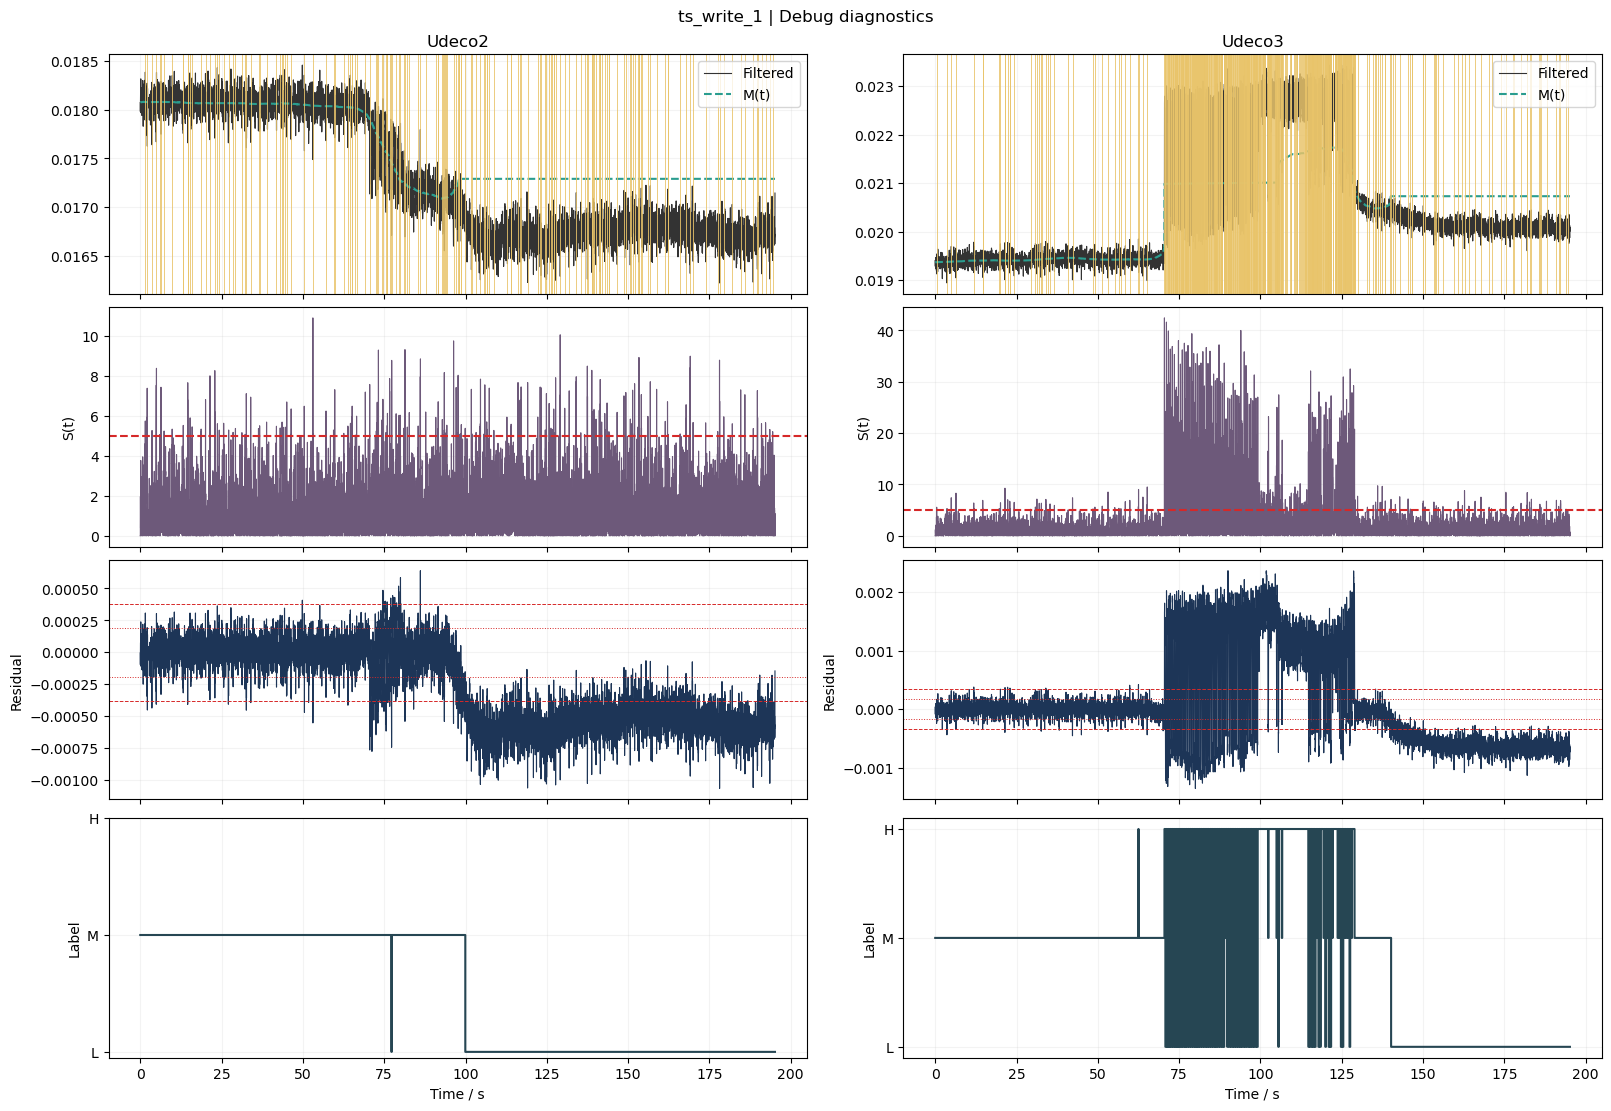

In [6]:
# Cell 4 - 单文件双通道完整分类与主/调试图
validation_result = None
validation_main_fig = None
validation_debug_fig = None
if VALIDATION_FILE is None or not VALIDATION_FILE.is_file():
    print('未提供可用 VALIDATION_FILE：Validation 安全跳过。')
else:
    validation_result = analyze_sample(VALIDATION_FILE, data_root=DATA_ROOT, fs=FS_HZ, config=CONFIG)
    validation_main_fig, validation_debug_fig = plot_validation(
        validation_result, show_debug_info=SHOW_DEBUG_INFO
    )
    plt.show()

### Validation 数值检查

同时检查最终统计、自然 segment、S(t)、M(t) 与 residual。若图形错误，先定位变化点、M(t)、中心判断还是滞回阈值。

In [7]:
if validation_result is not None:
    validation_stats = pd.DataFrame(
        [validation_result['channels'][name]['statistics'] for name in ('Udeco2', 'Udeco3')]
    )
    display(validation_stats)
    for channel_name in ('Udeco2', 'Udeco3'):
        print(f'--- {channel_name} segments ---')
        display(validation_result['channels'][channel_name]['segments'].head(30))
else:
    print('无 validation_result。')

,H_mean,H_std,H_total_duration,M_mean,M_std,M_total_duration,L_mean,L_std,L_total_duration,n_detected_states,...,sigma_M,state_separation,QC_flag,sample_name,subject,channel,analysis_status,error_message,motion_start_s,motion_end_s
0,NaN,NaN,NaN,0.017825,0.000418,99.84,0.016738,0.000167,95.31,2,...,0.000095,5.859883,OK,ts_write_1,ts,Udeco2,ok,,62.0,130.0
1,0.022586,0.000368,43.34,0.019616,0.000486,83.86,0.020185,0.000273,67.95,3,...,0.000086,7.203996,direct_H_to_L;direct_L_to_H,ts_write_1,ts,Udeco3,ok,,62.0,130.0


--- Udeco2 segments ---


,segment_id,start_idx,end_idx,start_time,end_time,duration,median,mean,std,MAD,filtered_median,initial_label,residual_median,trusted_m,final_label,platform_ok
0,0,0,155,0.00,1.55,1.55,0.018072,0.018082,0.000139,0.000077,0.018078,M,2.626616e-07,True,M,True
1,1,155,213,1.55,2.13,0.58,0.018101,0.018109,0.000141,0.000073,0.018098,M,2.024468e-05,True,M,True
2,2,213,362,2.13,3.62,1.49,0.018068,0.018047,0.000164,0.000066,0.018073,M,-5.076435e-06,True,M,True
3,3,362,497,3.62,4.97,1.35,0.018073,0.018081,0.000143,0.000079,0.018074,M,-3.420796e-06,True,M,True
4,4,497,596,4.97,5.96,0.99,0.018118,0.018121,0.000122,0.000093,0.018122,M,4.426776e-05,True,M,True
5,5,596,637,5.96,6.37,0.41,0.018056,0.018078,0.000154,0.000069,0.018056,M,-2.192937e-05,True,M,True
6,6,637,732,6.37,7.32,0.95,0.018072,0.018064,0.000137,0.000073,0.018077,M,-5.114713e-07,True,M,True
7,7,732,980,7.32,9.80,2.48,0.018074,0.018076,0.000137,0.000084,0.018075,M,-3.290777e-06,True,M,True
8,8,980,1322,9.80,13.22,3.42,0.018082,0.018088,0.000140,0.000077,0.018079,M,4.600145e-06,True,M,True
9,9,1322,1328,13.22,13.28,0.06,0.018028,0.017961,0.000252,0.000155,0.018028,M,-4.572403e-05,True,M,True


--- Udeco3 segments ---


,segment_id,start_idx,end_idx,start_time,end_time,duration,median,mean,std,MAD,filtered_median,initial_label,residual_median,trusted_m,final_label,platform_ok
0,0,0,44,0.00,0.44,0.44,0.019370,0.019348,0.000140,0.000083,0.019370,M,1.090179e-06,True,M,True
1,1,44,362,0.44,3.62,3.18,0.019365,0.019361,0.000139,0.000079,0.019363,M,-8.490171e-06,True,M,True
2,2,362,493,3.62,4.93,1.31,0.019365,0.019366,0.000125,0.000080,0.019365,M,-1.360554e-05,True,M,True
3,3,493,637,4.93,6.37,1.44,0.019403,0.019409,0.000152,0.000078,0.019404,M,2.020496e-05,True,M,True
4,4,637,1184,6.37,11.84,5.47,0.019389,0.019396,0.000132,0.000078,0.019386,M,-9.580576e-06,True,M,True
5,5,1184,1455,11.84,14.55,2.71,0.019413,0.019416,0.000136,0.000074,0.019409,M,7.329132e-06,True,M,True
6,6,1455,1460,14.55,14.60,0.05,0.019103,0.019075,0.000067,0.000038,0.019103,M,-2.997523e-04,True,M,False
7,7,1460,1970,14.60,19.70,5.10,0.019408,0.019415,0.000140,0.000082,0.019405,M,2.658563e-06,True,M,True
8,8,1970,2004,19.70,20.04,0.34,0.019378,0.019375,0.000108,0.000063,0.019373,M,-3.117992e-05,True,M,True
9,9,2004,2140,20.04,21.40,1.36,0.019396,0.019415,0.000134,0.000073,0.019393,M,-1.040900e-05,True,M,True


## 批量分析

仅在单文件图确认后设置 `RUN_BATCH=True`。Udeco2/Udeco3 独立分类；单样本错误保留为 NaN/QC 行，不阻断其余样本。

In [ ]:
# Cell 5 - 全部受试者批处理
batch_results = {}
if not RUN_BATCH:
    print('RUN_BATCH=False：跳过批量分析。')
else:
    batch_results = analyze_all_subjects(DATA_ROOT, SUBJECTS, fs=FS_HZ, config=CONFIG)
    batch_overview = pd.DataFrame([
        {
            'subject': subject,
            'sample_channel_rows': len(result['sample_results']),
            'ok_rows': int((result['sample_results']['analysis_status'] == 'ok').sum()),
            'qc_rows': len(result['qc']),
        }
        for subject, result in batch_results.items()
    ])
    display(batch_overview)

## Excel 输出

每个受试者一个 sheet：Part A 为样本宽表，Part B 为受试者 H/M/L 汇总，Part C 为跳过文件与 QC。

In [ ]:
# Cell 6 - Excel 仅在批处理结果存在时写出
excel_path = None
if batch_results:
    excel_path = export_excel(batch_results, OUTPUT_EXCEL)
    print(f'Excel 已输出：{excel_path.resolve()}')
else:
    print('无批处理结果：跳过 Excel。')

## 汇总检查

展示每个受试者 summary，并自动选择 M+H、M+L、最短非 M、最强运动、最大 M 漂移候选，供下一轮人工 Validation。

In [ ]:
if batch_results:
    for subject, result in batch_results.items():
        print(f'=== {subject} ===')
        display(result['summary'])
        if not result['qc'].empty:
            display(result['qc'].head(20))
    validation_candidates = select_validation_candidates(batch_results)
    print('推荐人工复核样本：')
    display(validation_candidates)
else:
    print('无批处理结果可汇总。')

## 下一步

1. 先确认单文件图中的短平台、变化点和 M(t)。
2. 如需调参，只修改用户参数区并重新构造 `CONFIG`。
3. 对推荐候选逐一替换 `VALIDATION_FILE`。
4. 参数确认后才开启批处理并保存 Excel。